In [5]:
# Customer EDA Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("customer_eda_dataset.csv")
print(df)


   Customer_ID  Age  Income Product_Category  Quantity   Sales  Discount  \
0         C001   22   24000      Electronics         2   42000         5   
1         C002   25   28000         Clothing         3   15000         8   
2         C003   29   35000        Furniture         1   28000        10   
3         C004   32   42000      Electronics         4   68000         7   
4         C005   35   48000          Grocery         6   18000         3   
5         C006   38   52000         Clothing         5   24000         6   
6         C007   41   58000        Furniture         2   52000        12   
7         C008   45   65000      Electronics         3   75000         8   
8         C009   48   72000          Grocery         8   26000         4   
9         C010   52   80000        Furniture         4   85000        15   
10        C011   27   31000         Clothing         2   11000         5   
11        C012   31   39000      Electronics         3   55000         6   
12        C0

In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


Product Category Frequency:


Product_Category
Electronics    15
Furniture      14
Clothing       11
Grocery        10
Name: count, dtype: int64

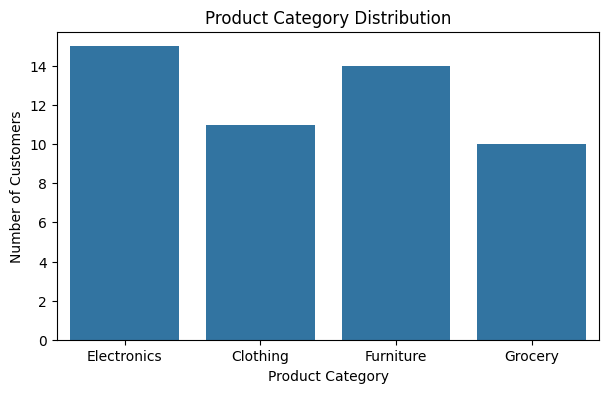

In [ ]:
# Univariate Analysis - categorical variable
print("Product Category Frequency:")
display(df['Product_Category'].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Product_Category')
plt.title('Product Category Distribution')
plt.xlabel('Product Category')
plt.ylabel('Number of Customers')
plt.show()

# x → the column you want to display on the X-axis
# data → the DataFrame you are using
# countplot() = Category-wise count/frequency.

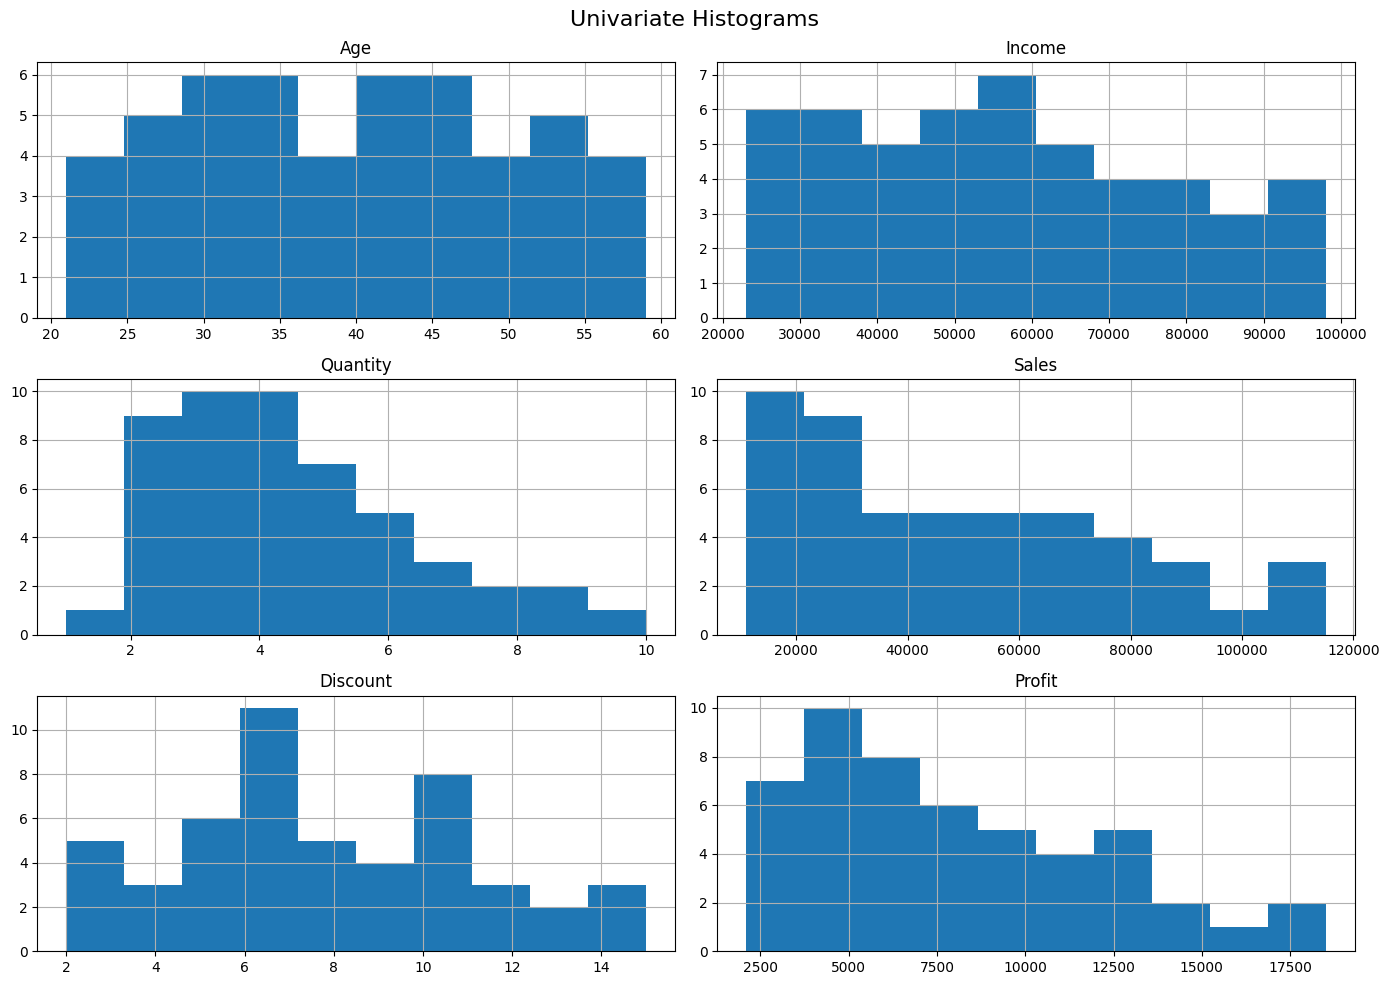

In [25]:
# Univariate Analysis - numerical variables
numeric_cols = ['Age', 'Income', 'Quantity', 'Sales', 'Discount', 'Profit']

df[numeric_cols].hist(figsize=(14, 10), bins=10,grid=True)
plt.suptitle('Univariate Histograms', fontsize=16)
plt.tight_layout()
plt.show()


In [8]:
# Mean, Median and Standard Deviation
summary_stats = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Standard_Deviation': df[numeric_cols].std()
})

display(summary_stats)


,Mean,Median,Standard_Deviation
Age,39.68,39.5,10.653044
Income,56340.00,54500.0,21151.166321
Quantity,4.38,4.0,2.117854
Sales,49360.00,44500.0,28343.202763
Discount,7.80,7.5,3.338092
Profit,7896.00,7050.0,4121.568950


In [9]:
# Skewness and Kurtosis
distribution_stats = pd.DataFrame({
    'Skewness': df[numeric_cols].skew(),
    'Kurtosis': df[numeric_cols].kurt()
})

display(distribution_stats)


,Skewness,Kurtosis
Age,0.058485,-1.046753
Income,0.253593,-0.936948
Quantity,0.804996,0.114943
Sales,0.572814,-0.663338
Discount,0.260617,-0.704467
Profit,0.716985,-0.227114


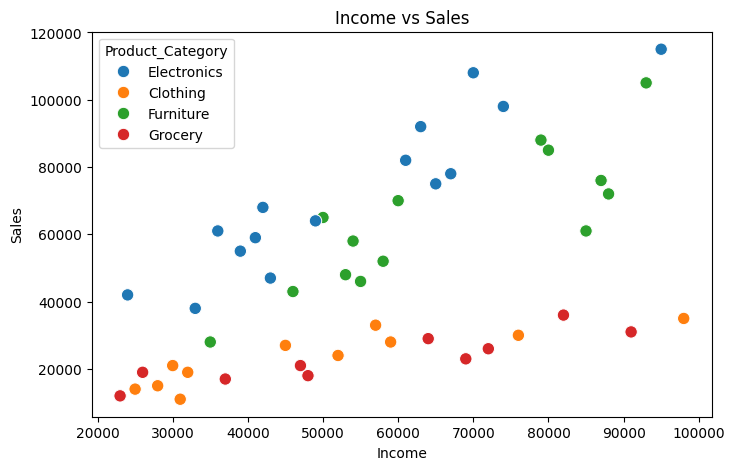

In [10]:
# Bivariate Analysis - Income vs Sales
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Income', y='Sales', hue='Product_Category', s=80)
plt.title('Income vs Sales')
plt.xlabel('Income')
plt.ylabel('Sales')
plt.show()


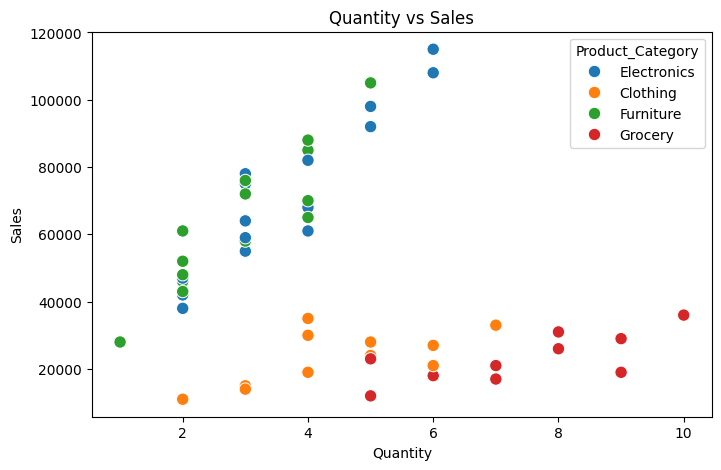

In [11]:
# Bivariate Analysis - Quantity vs Sales
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Quantity', y='Sales', hue='Product_Category', s=80)
plt.title('Quantity vs Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.show()


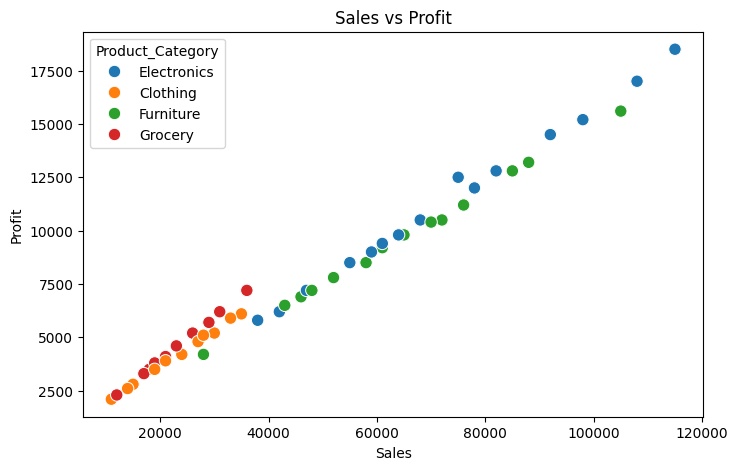

In [12]:
# Bivariate Analysis - Sales vs Profit
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sales', y='Profit', hue='Product_Category', s=80)
plt.title('Sales vs Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.show()


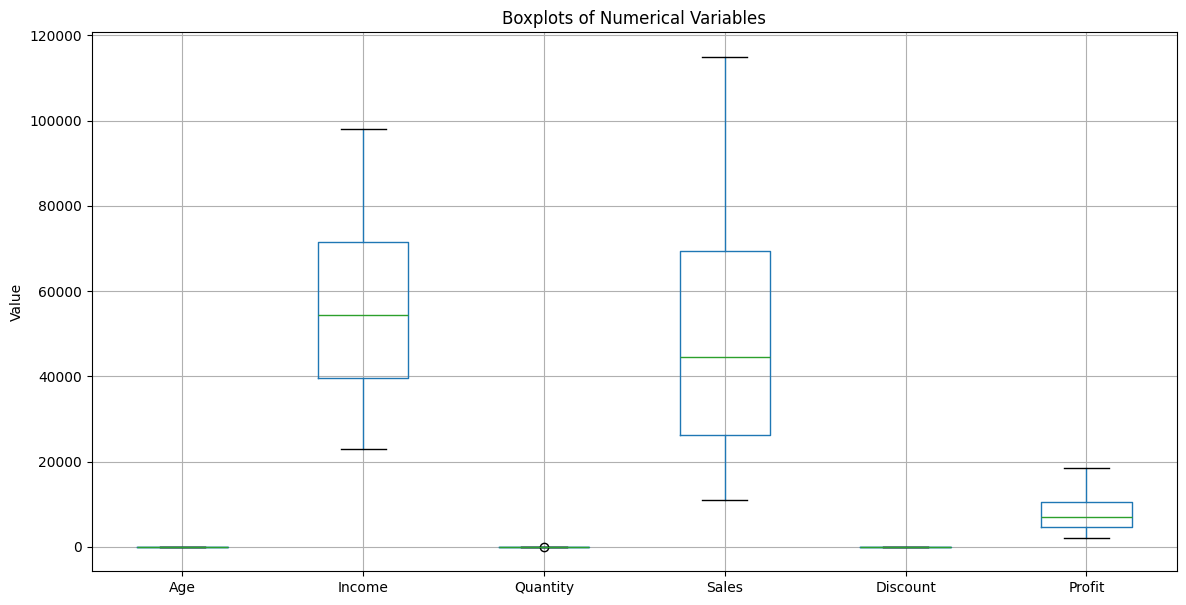

In [26]:
# Boxplots - numerical variables
plt.figure(figsize=(14, 7))
df[numeric_cols].boxplot()
plt.title('Boxplots of Numerical Variables')
plt.ylabel('Value')
plt.show()


Sales                Profit              
                      sum          mean     sum          mean
Product_Category                                             
Clothing           257000  23363.636364   46200   4200.000000
Electronics       1082000  72133.333333  168900  11260.000000
Furniture          897000  64071.428571  133800   9557.142857
Grocery            232000  23200.000000   45900   4590.000000

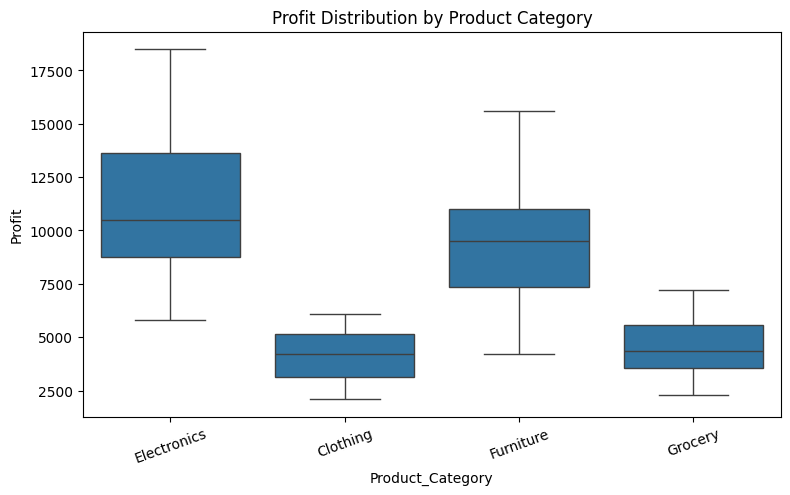

In [14]:
# Category-wise Sales and Profit
category_summary = df.groupby('Product_Category')[['Sales', 'Profit']].agg(['sum', 'mean'])
display(category_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Product_Category', y='Profit')
plt.title('Profit Distribution by Product Category')
plt.xticks(rotation=20)
plt.show()


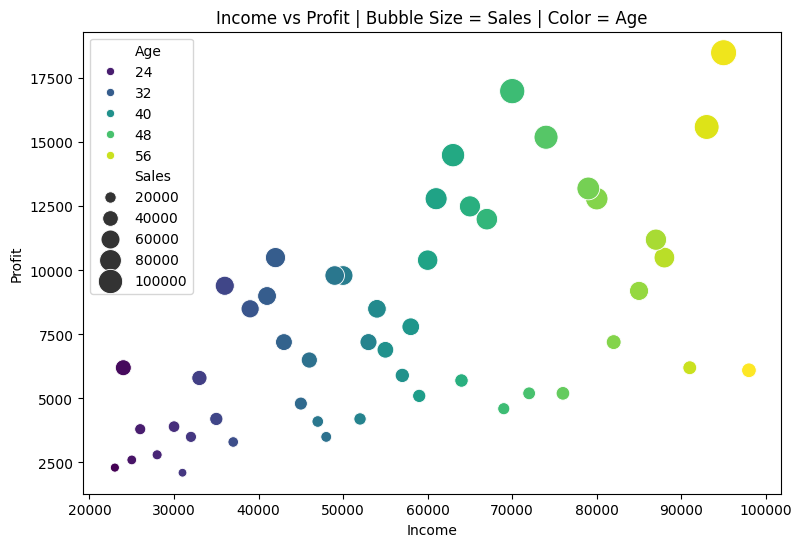

In [15]:
# Multivariate Analysis - Age, Income, Sales and Profit
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Income',
    y='Profit',
    size='Sales',
    hue='Age',
    sizes=(40, 350),
    palette='viridis'
)
plt.title('Income vs Profit | Bubble Size = Sales | Color = Age')
plt.show()


In [16]:
# Correlation Matrix
corr_matrix = df[numeric_cols].corr()
display(corr_matrix)


,Age,Income,Quantity,Sales,Discount,Profit
Age,1.000000,0.997151,0.206311,0.561385,0.588127,0.599146
Income,0.997151,1.000000,0.205717,0.554786,0.588908,0.591875
Quantity,0.206311,0.205717,1.000000,-0.172318,-0.427817,-0.081185
Sales,0.561385,0.554786,-0.172318,1.000000,0.620708,0.993146
Discount,0.588127,0.588908,-0.427817,0.620708,1.000000,0.575480
Profit,0.599146,0.591875,-0.081185,0.993146,0.575480,1.000000


In [17]:
# Covariance Matrix
cov_matrix = df[numeric_cols].cov()
display(cov_matrix)


,Age,Income,Quantity,Sales,Discount,Profit
Age,113.487347,2.246824e+05,4.654694,1.695053e+05,20.914286,2.630686e+04
Income,224682.448980,4.473718e+08,9215.102041,3.325894e+08,41579.591837,5.159731e+07
Quantity,4.654694,9.215102e+03,4.485306,-1.034367e+04,-3.024490,-7.086531e+02
Sales,169505.306122,3.325894e+08,-10343.673469,8.033371e+08,58726.530612,1.160178e+08
Discount,20.914286,4.157959e+04,-3.024490,5.872653e+04,11.142857,7.917551e+03
Profit,26306.857143,5.159731e+07,-708.653061,1.160178e+08,7917.551020,1.698733e+07


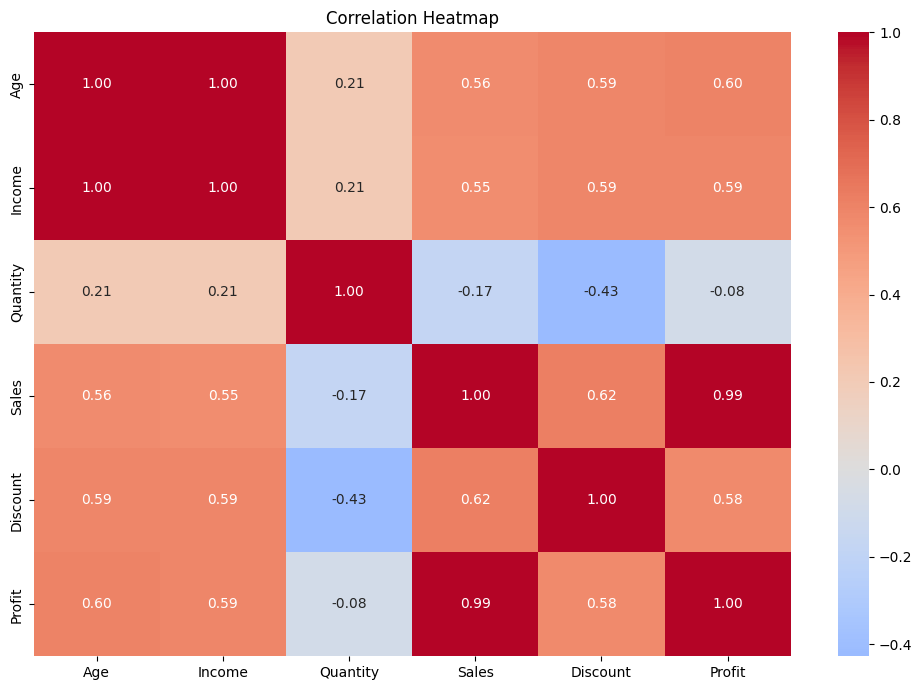

In [18]:
# Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [20]:
# Five Business Insights
category_sales = df.groupby('Product_Category')['Sales'].sum().sort_values(ascending=False)
category_profit = df.groupby('Product_Category')['Profit'].sum().sort_values(ascending=False)

insights = [
    f"1. Income and Sales: The correlation between Income and Sales is {corr_matrix.loc['Income','Sales']:.2f}, indicating the strength and direction of their linear relationship.",
    f"2. Sales and Profit: The correlation between Sales and Profit is {corr_matrix.loc['Sales','Profit']:.2f}, showing how strongly profit changes with sales.",
    f"3. Quantity and Sales: The correlation between Quantity and Sales is {corr_matrix.loc['Quantity','Sales']:.2f}, which helps assess whether larger purchase quantities are associated with higher sales.",
    f"4. Discount and Profit: The correlation between Discount and Profit is {corr_matrix.loc['Discount','Profit']:.2f}. This can be used to evaluate the relationship between discount levels and profit.",
    f"5. Product Category: {category_sales.index[0]} has the highest total sales in this dataset, while {category_profit.index[0]} has the highest total profit."
]

for insight in insights:
    print(insight)


1. Income and Sales: The correlation between Income and Sales is 0.55, indicating the strength and direction of their linear relationship.
2. Sales and Profit: The correlation between Sales and Profit is 0.99, showing how strongly profit changes with sales.
3. Quantity and Sales: The correlation between Quantity and Sales is -0.17, which helps assess whether larger purchase quantities are associated with higher sales.
4. Discount and Profit: The correlation between Discount and Profit is 0.58. This can be used to evaluate the relationship between discount levels and profit.
5. Product Category: Electronics has the highest total sales in this dataset, while Electronics has the highest total profit.


In [21]:
# Final descriptive summary
print("EDA completed successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print("Numerical columns:", numeric_cols)


EDA completed successfully.
Rows: 50
Columns: 8
Numerical columns: ['Age', 'Income', 'Quantity', 'Sales', 'Discount', 'Profit']
